In [1]:
import pandas as pd
import os

In [24]:
pd.set_option('display.max_colwidth',200)

### Loading the data

In [41]:


base_path = "/home/toastu/Projects/Bit/data/archive/LA/LA/"
dev_protocol_path = os.path.join(base_path, "ASVspoof2019_LA_cm_protocols", "ASVspoof2019.LA.cm.dev.trl.txt")
dev_audio_folder = os.path.join(base_path, "ASVspoof2019_LA_dev", "flac")

# collumns based on the README of the original dataset
columns = ["speaker_id", "audio_file_name", "ignored", "system_id", "label"]

df_dev = pd.read_csv(dev_protocol_path, sep=" ", header=None, names=columns)

df_dev = df_dev.drop(columns=["ignored"])


df_dev['file_path'] = df_dev['audio_file_name'].apply(lambda x: os.path.join(dev_audio_folder, x + ".flac"))

df_dev.sample(10)

,speaker_id,audio_file_name,system_id,label,file_path
19861,LA_0075,LA_D_7155652,A05,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_7155652.flac
19778,LA_0075,LA_D_5185211,A05,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_5185211.flac
10645,LA_0070,LA_D_8540960,A03,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_8540960.flac
3467,LA_0071,LA_D_6948051,A01,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_6948051.flac
1966,LA_0103,LA_D_9851890,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9851890.flac
20318,LA_0077,LA_D_1533885,A05,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1533885.flac
22058,LA_0071,LA_D_6842546,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_6842546.flac
4654,LA_0074,LA_D_8505020,A01,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_8505020.flac
7511,LA_0072,LA_D_6080461,A02,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_6080461.flac
11896,LA_0074,LA_D_4415743,A03,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_4415743.flac


In [42]:
df_dev

,speaker_id,audio_file_name,system_id,label,file_path
0,LA_0069,LA_D_1047731,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac
1,LA_0069,LA_D_1105538,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1105538.flac
2,LA_0069,LA_D_1125976,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1125976.flac
3,LA_0069,LA_D_1293230,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1293230.flac
4,LA_0069,LA_D_1340209,-,bonafide,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1340209.flac
...,...,...,...,...,...
24839,LA_0078,LA_D_9924204,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9924204.flac
24840,LA_0078,LA_D_9931163,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9931163.flac
24841,LA_0078,LA_D_9935163,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9935163.flac
24842,LA_0078,LA_D_9944718,A06,spoof,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9944718.flac


### Data cleaning

In [43]:

df_dev['label'] = df_dev['label'].map({'bonafide': 0, 'spoof': 1})

df_dev = df_dev.drop(columns=['audio_file_name'])

#sanity check
df_dev['file_exists'] = df_dev['file_path'].apply(os.path.exists)
print(f"Missing files: {len(df_dev[df_dev['file_exists'] == False])}")
df_dev

Missing files: 0


,speaker_id,system_id,label,file_path,file_exists
0,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac,True
1,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1105538.flac,True
2,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1125976.flac,True
3,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1293230.flac,True
4,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1340209.flac,True
...,...,...,...,...,...
24839,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9924204.flac,True
24840,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9931163.flac,True
24841,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9935163.flac,True
24842,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9944718.flac,True


In [44]:
df_dev = df_dev.drop(columns=['file_exists'])

In [45]:
df_dev

,speaker_id,system_id,label,file_path
0,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac
1,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1105538.flac
2,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1125976.flac
3,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1293230.flac
4,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1340209.flac
...,...,...,...,...
24839,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9924204.flac
24840,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9931163.flac
24841,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9935163.flac
24842,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9944718.flac


In [46]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

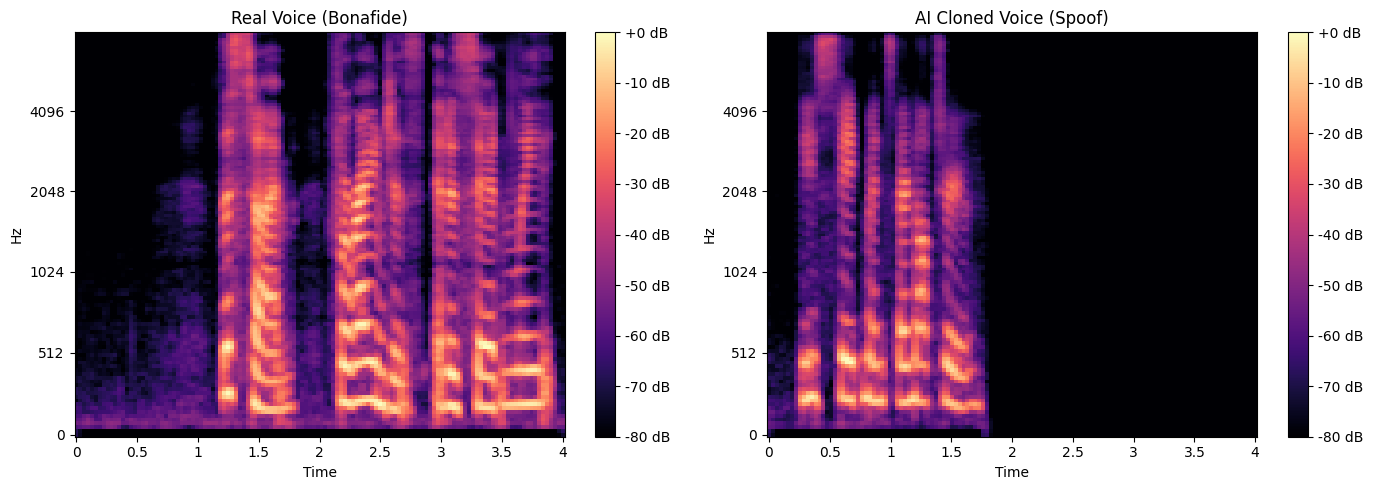

In [47]:
def generate_mel_spectrogram(file_path, target_seconds=4, sample_rate=16000):
    
    target_length = target_seconds * sample_rate
    
    
    y, sr = librosa.load(file_path, sr=sample_rate)
    
    
    y_fixed = librosa.util.fix_length(data=y, size=target_length)
    
    
    mel_spec = librosa.feature.melspectrogram(y=y_fixed, sr=sr, n_mels=128)
    
   
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
    
    return mel_spec_db


sample_real_path = df_dev[df_dev['label'] == 0].iloc[0]['file_path']
sample_fake_path = df_dev[df_dev['label'] == 1].iloc[0]['file_path']


spec_real = generate_mel_spectrogram(sample_real_path)
spec_fake = generate_mel_spectrogram(sample_fake_path)


fig, ax = plt.subplots(1, 2, figsize=(14, 5))

img1 = librosa.display.specshow(spec_real, sr=16000, x_axis='time', y_axis='mel', ax=ax[0])
ax[0].set_title('Real Voice (Bonafide)')
fig.colorbar(img1, ax=ax[0], format='%+2.0f dB')

img2 = librosa.display.specshow(spec_fake, sr=16000, x_axis='time', y_axis='mel', ax=ax[1])
ax[1].set_title('AI Cloned Voice (Spoof)')
fig.colorbar(img2, ax=ax[1], format='%+2.0f dB')

plt.tight_layout()
plt.show()

In [48]:
from tqdm import tqdm

In [49]:
df_dev_img = df_dev.copy()
df_dev_img

,speaker_id,system_id,label,file_path
0,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac
1,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1105538.flac
2,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1125976.flac
3,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1293230.flac
4,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1340209.flac
...,...,...,...,...
24839,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9924204.flac
24840,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9931163.flac
24841,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9935163.flac
24842,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9944718.flac


In [50]:

output_base_dir = "data/dataset_img/dev"

def compute_img_path(row):
    subfolder = "real" if row['label'] == 0 else "fake"
    return os.path.join(output_base_dir, subfolder, f"sample_{row.name}.png")


df_dev_img['img_path'] = df_dev_img.apply(compute_img_path, axis=1)

os.makedirs(os.path.join(output_base_dir, "real"), exist_ok=True)
os.makedirs(os.path.join(output_base_dir, "fake"), exist_ok=True)

print("Starting Mel-spectrogram export to disk...")


for idx, row in tqdm(df_dev.iterrows(), total=len(df_dev)):
    file_path = row['file_path']
    label = row['label']
    
    try:
        
        spec_db = generate_mel_spectrogram(file_path)
        
        
        if label == 0:
            dest_folder = os.path.join(output_base_dir, "real")
        else:
            dest_folder = os.path.join(output_base_dir, "fake")
            
        
        img_filename = f"sample_{idx}.png"
        img_path = os.path.join(dest_folder, img_filename)
        
        
        plt.imsave(img_path, spec_db, cmap='magma', origin='lower')
        
    except Exception as e:
        print(f"Error processing index {idx} ({file_path}): {e}")
        continue

print(f"Export complete! Check your directory: {output_base_dir}")

Starting Mel-spectrogram export to disk...


100%|█████████████████████████████████████████████| 24844/24844 [04:07<00:00, 100.36it/s]

Export complete! Check your directory: data/dataset_img/dev


In [51]:
df_dev_img

,speaker_id,system_id,label,file_path,img_path
0,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1047731.flac,data/dataset_img/dev/real/sample_0.png
1,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1105538.flac,data/dataset_img/dev/real/sample_1.png
2,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1125976.flac,data/dataset_img/dev/real/sample_2.png
3,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1293230.flac,data/dataset_img/dev/real/sample_3.png
4,LA_0069,-,0,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_1340209.flac,data/dataset_img/dev/real/sample_4.png
...,...,...,...,...,...
24839,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9924204.flac,data/dataset_img/dev/fake/sample_24839.png
24840,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9931163.flac,data/dataset_img/dev/fake/sample_24840.png
24841,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9935163.flac,data/dataset_img/dev/fake/sample_24841.png
24842,LA_0078,A06,1,/home/toastu/Projects/Bit/data/archive/LA/LA/ASVspoof2019_LA_dev/flac/LA_D_9944718.flac,data/dataset_img/dev/fake/sample_24842.png


In [52]:
df_export = df_dev_img.drop(columns = ['file_path'])
df_export

,speaker_id,system_id,label,img_path
0,LA_0069,-,0,data/dataset_img/dev/real/sample_0.png
1,LA_0069,-,0,data/dataset_img/dev/real/sample_1.png
2,LA_0069,-,0,data/dataset_img/dev/real/sample_2.png
3,LA_0069,-,0,data/dataset_img/dev/real/sample_3.png
4,LA_0069,-,0,data/dataset_img/dev/real/sample_4.png
...,...,...,...,...
24839,LA_0078,A06,1,data/dataset_img/dev/fake/sample_24839.png
24840,LA_0078,A06,1,data/dataset_img/dev/fake/sample_24840.png
24841,LA_0078,A06,1,data/dataset_img/dev/fake/sample_24841.png
24842,LA_0078,A06,1,data/dataset_img/dev/fake/sample_24842.png


In [53]:
df_export.to_csv("data/metadata_dev.csv", index = False)